# Задача 3

Вычислить интеграл

$$
I_{3a}=\int_{-1}^{1} \frac{dx}{1+x^2},
$$

методами левых и правых прямоугольников, средних, трапеций и Симпсона. Проанализировать порядок точности методов. Написать программу, вычисляющую значения интеграла и ошибок.

$$
\operatorname{erf}(x)=\frac{2}{\sqrt{\pi}}\int_0^x e^{-t^2}\,dt,
$$

где $\operatorname{erf}(x)$ — функция ошибок.

---

## Пункт А: Вычисление интеграла.

### Точное значение и обозначения:

Используем формулы из лекции «Численное интегрирование» от 15.09.
Для проверки численных результатов сначала найдём точное значение:

$$
    I=\int_{-1}^{1}\frac{dx}{1+x^2}
    =\left.\arctan x\right|_{-1}^{1}
    =\frac{\pi}{2}.
$$

Разобьём отрезок $[a,b]$ на $N$ одинаковых интервалов:

$$
    h=\frac{b-a}{N}, \qquad x_i=a+ih, \qquad
    c_i=\frac{x_{i-1}+x_i}{2}, \qquad i=1,\ldots,N.
$$

Здесь $a=-1$, $b=1$, $f(x)=1/(1+x^2)$.
Как в лекции, обозначим численное значение через $S_h$, а остаточный член через

$$
    R(h)=I-S_h, \qquad \delta(h)=|R(h)|.
$$

Под каждым методом будем выводить и остаточный член со знаком, и абсолютную ошибку.

In [85]:
import math
import numpy as np
import matplotlib.pyplot as plt

a = -1
b = 1
N = 64
I_exact = math.pi / 2

def f(x):
    return 1 / (1 + x**2)

## Метод левых прямоугольников.

На каждом интервале заменяем функцию её значением в левом конце:

$$
    S_h^{(L)}=h\sum_{i=1}^{N}f(x_{i-1}).
$$

In [86]:
def find_left(func, a, b, N):
    h = (b - a) / N
    total = 0
    for i in range(N):
        x = a + i * h
        total += func(x)
    return h * total

result = find_left(f, a, b, N)
print("Интеграл:", result)
print("Остаток I - S:", I_exact - result)
print("Абсолютная ошибка:", abs(I_exact - result))

Интеграл: 1.5707149465874863
Остаток I - S: 8.13802074102199e-05
Абсолютная ошибка: 8.13802074102199e-05


## Метод правых прямоугольников.

Теперь используем значение функции в правом конце:

$$
    S_h^{(R)}=h\sum_{i=1}^{N}f(x_i).
$$

In [87]:
def find_right(func, a, b, N):
    h = (b - a) / N
    total = 0
    for i in range(1, N + 1):
        x = a + i * h
        total += func(x)
    return h * total

result = find_right(f, a, b, N)
print("Интеграл:", result)
print("Остаток I - S:", I_exact - result)
print("Абсолютная ошибка:", abs(I_exact - result))

Интеграл: 1.5707149465874863
Остаток I - S: 8.13802074102199e-05
Абсолютная ошибка: 8.13802074102199e-05


## Формула средних.

Высоту прямоугольника берём в середине интервала:

$$
    S_h^{(M)}=h\sum_{i=1}^{N}f(c_i).
$$

In [88]:
def find_midpoint(func, a, b, N):
    h = (b - a) / N
    total = 0
    for i in range(N):
        x = a + (i + 0.5) * h
        total += func(x)
    return h * total

result = find_midpoint(f, a, b, N)
print("Интеграл:", result)
print("Остаток I - S:", I_exact - result)
print("Абсолютная ошибка:", abs(I_exact - result))

Интеграл: 1.5708370168981678
Остаток I - S: -4.069010327123479e-05
Абсолютная ошибка: 4.069010327123479e-05


## Метод трапеций.

Заменяем график функции хордой на каждом интервале:

$$
    S_h^{(T)}=h\sum_{i=1}^{N}\frac{f(x_{i-1})+f(x_i)}{2}.
$$

In [89]:
def find_trapezoid(func, a, b, N):
    h = (b - a) / N
    total = 0
    for i in range(N):
        x1 = a + i * h
        x2 = a + (i + 1) * h
        total += (func(x1) + func(x2)) / 2
    return h * total

result = find_trapezoid(f, a, b, N)
print("Интеграл:", result)
print("Остаток I - S:", I_exact - result)
print("Абсолютная ошибка:", abs(I_exact - result))

Интеграл: 1.5707149465874872
Остаток I - S: 8.138020740933172e-05
Абсолютная ошибка: 8.138020740933172e-05


## Метод Симпсона.

Как в лекции, на каждом интервале используем два конца и середину:

$$
    S_h^{(S)}=\frac{h}{6}\sum_{i=1}^{N}
    \left[f(x_{i-1})+4f(c_i)+f(x_i)\right]
    =\frac{S_h^{(T)}+2S_h^{(M)}}{3}.
$$

Здесь $h$ — ширина целого интервала, а не расстояние до середины.
Поэтому коэффициент равен $h/6$. Число $N$ может быть любым положительным
целым: на каждом из $N$ интервалов дополнительно берётся середина.

In [90]:
def find_simpson(func, a, b, N):
    h = (b - a) / N
    total = 0
    for i in range(N):
        x1 = a + i * h
        x2 = a + (i + 1) * h
        middle = (x1 + x2) / 2
        total += func(x1) + 4 * func(middle) + func(x2)
    return h * total / 6

result = find_simpson(f, a, b, N)
print("Интеграл:", result)
print("Остаток I - S:", I_exact - result)
print("Абсолютная ошибка:", abs(I_exact - result))

Интеграл: 1.5707963267946077
Остаток I - S: 2.8888003100746573e-13
Абсолютная ошибка: 2.8888003100746573e-13


## Сравнение результатов.

Вычислим интеграл всеми пятью методами при $N=64$.
Параметры можно изменить в первой ячейке с кодом и выполнить ячейки заново.

In [91]:
# Название и функция для каждого метода.
methods = [
    ("Левые", find_left),
    ("Правые", find_right),
    ("Средние", find_midpoint),
    ("Трапеции", find_trapezoid),
    ("Симпсон", find_simpson),
]

print("Точное значение:", I_exact)
print("Число интервалов:", N)

for name, method in methods:
    result = method(f, a, b, N)
    error = I_exact - result
    print(f"{name}: S = {result:.12f}, R = {error:.3e}, ошибка = {abs(error):.3e}")

Точное значение: 1.5707963267948966
Число интервалов: 64
Левые: S = 1.570714946587, R = 8.138e-05, ошибка = 8.138e-05
Правые: S = 1.570714946587, R = 8.138e-05, ошибка = 8.138e-05
Средние: S = 1.570837016898, R = -4.069e-05, ошибка = 4.069e-05
Трапеции: S = 1.570714946587, R = 8.138e-05, ошибка = 8.138e-05
Симпсон: S = 1.570796326795, R = 2.889e-13, ошибка = 2.889e-13


## Порядок точности методов.

### Теоретические оценки из лекции:

Для достаточно гладкой функции остаточные члены имеют вид

$$
\begin{aligned}
    R_L(h)&=\frac{h}{2}[f(b)-f(a)]+O(h^2),\\
    R_R(h)&=-\frac{h}{2}[f(b)-f(a)]+O(h^2),\\
    R_T(h)&=-\frac{h^2}{12}[f'(b)-f'(a)]+O(h^4),\\
    R_M(h)&=\frac{h^2}{24}[f'(b)-f'(a)]+O(h^4),\\
    R_S(h)&=-\frac{h^4}{2880}[f'''(b)-f'''(a)]+O(h^6).
\end{aligned}
$$

Следовательно, в общем случае левые и правые прямоугольники имеют первый
порядок, средние и трапеции — второй, Симпсон — четвёртый.
Если коэффициент главного члена ошибки равен нулю, на конкретной задаче
может наблюдаться более высокий порядок.

### Особенность левых и правых прямоугольников:

В нашей задаче $f(-1)=f(1)=1/2$, поэтому

$$
    S_h^{(R)}-S_h^{(L)}=h[f(b)-f(a)]=0.
$$

Кроме того,

$$
    S_h^{(T)}=\frac{S_h^{(L)}+S_h^{(R)}}{2}.
$$

Таким образом, для любой такой сетки

$$
    S_h^{(L)}=S_h^{(R)}=S_h^{(T)}
$$

в точной арифметике. При вычислениях возможны различия на уровне округления.
Член ошибки порядка $h$ исчезает, и оба метода прямоугольников здесь
имеют **второй порядок**.

Для нашей функции

$$
    f'(x)=-\frac{2x}{(1+x^2)^2}, \qquad
    f'(1)-f'(-1)=-1.
$$

Поэтому

$$
    R_L(h)=R_R(h)=R_T(h)=\frac{h^2}{12}+O(h^4), \qquad
    R_M(h)=-\frac{h^2}{24}+O(h^4).
$$

При достаточно мелкой сетке левые, правые и трапеции дают значение ниже
точного, а средние — выше. Ошибка средних примерно вдвое меньше ошибки трапеций.

### Особенность метода Симпсона:

Вычислим третью производную:

$$
    f'''(x)=\frac{24x(1-x^2)}{(1+x^2)^4}, \qquad
    f'''(-1)=f'''(1)=0.
$$

По лекционной формуле главный член ошибки Симпсона также равен нулю:

$$
    R_S(h)=-\frac{h^4}{2880}[f'''(1)-f'''(-1)]+O(h^6)
    =O(h^6).
$$

Для этого интеграла наблюдается **шестой порядок**. Это свойство выбранной
функции и границ интегрирования; общий порядок метода остаётся четвёртым.

### Численная проверка порядка:

Вычислим интеграл при разных числах интервалов $N$.
Если $\delta(h)\approx C h^p$, а $h=(b-a)/N$, то порядок можно оценить так:

$$
    p_{\mathrm{набл}}=
    \frac{\ln(\delta_{N_1}/\delta_{N_2})}{\ln(N_2/N_1)}.
$$

При удвоении $N$ эта формула превращается в
$p_{\mathrm{набл}}=\log_2(\delta_N/\delta_{2N})$.
Для второго порядка ошибка уменьшается примерно в $4$ раза, для шестого —
в $64$ раза. Формула в коде работает и при увеличении $N$ на единицу.
Для первой сетки предыдущей ошибки ещё нет, поэтому выводим прочерк.
На слишком мелких сетках ошибка Симпсона сравнивается с ошибкой округления,
и оценка порядка теряет смысл.

In [92]:
# При N = 2000 шаг h = 2 / 2000 = 0.001.
N_values = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 96,
                     128, 192, 256, 384, 512, 768, 1024, 1536, 2000])
errors_a = {}

for name, method in methods:
    print("\nМетод:", name)
    errors = []
    previous_error = 0
    previous_n = 0

    for n in N_values:
        result = method(f, a, b, n)
        error = abs(I_exact - result)
        errors.append(error)

        if previous_n == 0:
            order = "—"
        elif error < 1e-14 or previous_error < 1e-14:
            order = "ошибка слишком мала"
        else:
            order = math.log(previous_error / error) / math.log(n / previous_n)
            order = round(order, 3)

        print(f"N = {n}, ошибка = {error:.3e}, порядок = {order}")
        previous_error = error
        previous_n = n

    errors_a[name] = errors


Метод: Левые
N = 4, ошибка = 2.080e-02, порядок = —
N = 6, ошибка = 9.258e-03, порядок = 1.996
N = 8, ошибка = 5.208e-03, порядок = 2.0
N = 12, ошибка = 2.315e-03, порядок = 2.0
N = 16, ошибка = 1.302e-03, порядок = 2.0
N = 24, ошибка = 5.787e-04, порядок = 2.0
N = 32, ошибка = 3.255e-04, порядок = 2.0
N = 48, ошибка = 1.447e-04, порядок = 2.0
N = 64, ошибка = 8.138e-05, порядок = 2.0
N = 96, ошибка = 3.617e-05, порядок = 2.0
N = 128, ошибка = 2.035e-05, порядок = 2.0
N = 192, ошибка = 9.042e-06, порядок = 2.0
N = 256, ошибка = 5.086e-06, порядок = 2.0
N = 384, ошибка = 2.261e-06, порядок = 2.0
N = 512, ошибка = 1.272e-06, порядок = 2.0
N = 768, ошибка = 5.651e-07, порядок = 2.0
N = 1024, ошибка = 3.179e-07, порядок = 2.0
N = 1536, ошибка = 1.413e-07, порядок = 2.0
N = 2000, ошибка = 8.333e-08, порядок = 2.0

Метод: Правые
N = 4, ошибка = 2.080e-02, порядок = —
N = 6, ошибка = 9.258e-03, порядок = 1.996
N = 8, ошибка = 5.208e-03, порядок = 2.0
N = 12, ошибка = 2.315e-03, порядок = 2.0

### График ошибок:

Расчёт подтверждает второй порядок у левых, правых, средних и трапеций.
У Симпсона на грубой сетке оценка может отличаться от предельной;
при увеличении числа интервалов она приближается к шести.

На графике в двойном логарифмическом масштабе зависимость $\delta\sim h^p$
представляет собой прямую с наклоном $p$. Совпадающие ошибки левых,
правых прямоугольников и трапеций покажем одной линией.

Расчёты продолжаются до $h=10^{-3}$. На мелкой сетке ошибка Симпсона
достигает уровня округления чисел Python, поэтому линия может перестать
убывать. Когда ошибка меньше $10^{-14}$, численный порядок уже не оцениваем.

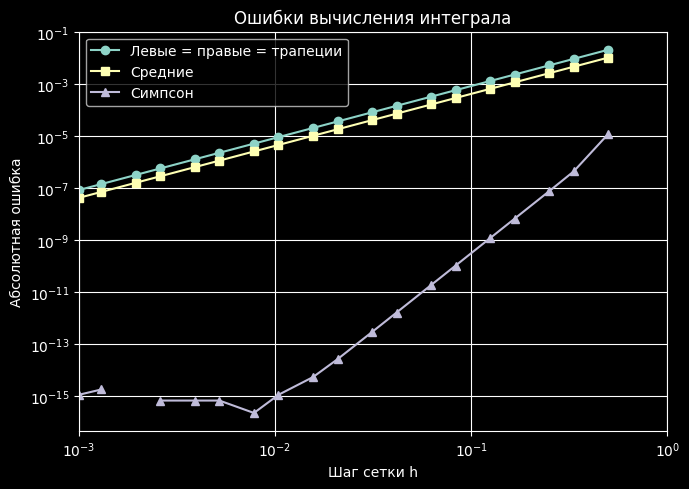

In [93]:
h_values = (b - a) / N_values

plt.figure(figsize=(7, 5))
plt.loglog(h_values, errors_a["Трапеции"], "o-", label="Левые = правые = трапеции")
plt.loglog(h_values, errors_a["Средние"], "s-", label="Средние")
plt.loglog(h_values, errors_a["Симпсон"], "^-", label="Симпсон")
# Нулевые ошибки пропускаем: логарифм нуля не определён.
plt.yscale("log", nonpositive="mask")
# Деления оси X: степени десяти от 10^-3 до 10^0.
plt.xlim(1e-3, 1)
plt.xticks([1e-3, 1e-2, 1e-1, 1],
           [r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^0$"])
plt.minorticks_off()
plt.xlabel("Шаг сетки h")
plt.ylabel("Абсолютная ошибка")
plt.title("Ошибки вычисления интеграла")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Пункт Б: Вычисление функции ошибок.

### Интегральное представление:

Вычислим функцию, указанную в условии:

$$
    \operatorname{erf}(x)=\frac{2}{\sqrt{\pi}}\int_0^x e^{-t^2}\,dt.
$$

Используем те же пять методов с подынтегральной функцией $g(t)=e^{-t^2}$,
границами $a=0$, $b=x$ и множителем $2/\sqrt{\pi}$.
Для проверки возьмём `math.erf(x)` из стандартной библиотеки Python;
сама программа интегрирует функцию нашими методами.

При $x<0$ шаг $h=x/N$ отрицателен, что автоматически учитывает направление
интегрирования. При $x=0$ интеграл равен нулю.

In [94]:
def g(t):
    return math.exp(-t**2)

def find_erf(x, N=64):
    integral = find_simpson(g, 0, x, N)
    return 2 / math.sqrt(math.pi) * integral

print("erf(1):", find_erf(1))
print("Абсолютная ошибка:", abs(math.erf(1) - find_erf(1)))

erf(1): 0.842700792984079
Абсолютная ошибка: 3.4364067147407695e-11


### Значения функции и ошибки:

Для примера возьмём $x=-2,-1,0,0.5,1,2$ и $N=64$.
Выведем значения, полученные методом Симпсона,
а ниже сравним все методы при $x=1$.

In [95]:
x_values = [-2, -1, 0, 0.5, 1, 2]
N_erf = 64

print("Метод Симпсона, N =", N_erf)
for x in x_values:
    result = find_erf(x, N_erf)
    exact = math.erf(x)
    error = abs(exact - result)
    print(f"x = {x}: erf = {result:.12f}, math.erf = {exact:.12f}, ошибка = {error:.3e}")

Метод Симпсона, N = 64
x = -2: erf = -0.995322264745, math.erf = -0.995322265019, ошибка = 2.737e-10
x = -1: erf = -0.842700792984, math.erf = -0.842700792950, ошибка = 3.436e-11
x = 0: erf = 0.000000000000, math.erf = 0.000000000000, ошибка = 0.000e+00
x = 0.5: erf = 0.520499877819, math.erf = 0.520499877813, ошибка = 5.684e-12
x = 1: erf = 0.842700792984, math.erf = 0.842700792950, ошибка = 3.436e-11
x = 2: erf = 0.995322264745, math.erf = 0.995322265019, ошибка = 2.737e-10


In [96]:
x_erf = 1
erf_exact = math.erf(x_erf)
coefficient = 2 / math.sqrt(math.pi)

print("Сравнение методов при x =", x_erf)
print("Точное значение:", erf_exact)

for name, method in methods:
    result = coefficient * method(g, 0, x_erf, N_erf)
    error = erf_exact - result
    print(f"{name}: erf = {result:.12f}, R = {error:.3e}, ошибка = {abs(error):.3e}")

Сравнение методов при x = 1
Точное значение: 0.8427007929497149
Левые: erf = 0.848256336964, R = -5.556e-03, ошибка = 5.556e-03
Правые: erf = 0.837111467126, R = 5.589e-03, ошибка = 5.589e-03
Средние: erf = 0.842709238454, R = -8.446e-06, ошибка = 8.446e-06
Трапеции: erf = 0.842683902045, R = 1.689e-05, ошибка = 1.689e-05
Симпсон: erf = 0.842700792984, R = -3.436e-11, ошибка = 3.436e-11


### Проверка обычного порядка точности:

На отрезке $[0,1]$ для $g(t)=e^{-t^2}$ имеем

$$
\begin{aligned}
    g(1)-g(0)&=e^{-1}-1\ne0,\\
    g'(1)-g'(0)&=-2e^{-1}\ne0,\\
    g'''(1)-g'''(0)&=4e^{-1}\ne0.
\end{aligned}
$$

Поэтому главные члены ошибок не исчезают. Ожидаем первый порядок
для левых и правых прямоугольников, второй — для средних и трапеций,
четвёртый — для Симпсона. Множитель $2/\sqrt{\pi}$ не меняет порядок.

In [97]:
# При N = 1000 шаг h = 1 / 1000 = 0.001.
N_values_erf = np.array([4, 6, 8, 12, 16, 24, 32, 48, 64, 96,
                         128, 192, 256, 384, 512, 768, 1000])
errors_erf = {}

for name, method in methods:
    print("\nМетод:", name)
    errors = []
    previous_error = 0
    previous_n = 0

    for n in N_values_erf:
        result = coefficient * method(g, 0, x_erf, n)
        error = abs(erf_exact - result)
        errors.append(error)

        if previous_n == 0:
            order = "—"
        elif error < 1e-14 or previous_error < 1e-14:
            order = "ошибка слишком мала"
        else:
            order = math.log(previous_error / error) / math.log(n / previous_n)
            order = round(order, 3)

        print(f"N = {n}, ошибка = {error:.3e}, порядок = {order}")
        previous_error = error
        previous_n = n

    errors_erf[name] = errors


Метод: Левые
N = 4, ошибка = 8.483e-02, порядок = —
N = 6, ошибка = 5.752e-02, порядок = 0.958
N = 8, ошибка = 4.350e-02, порядок = 0.971
N = 12, ошибка = 2.924e-02, порядок = 0.98
N = 16, ошибка = 2.202e-02, порядок = 0.986
N = 24, ошибка = 1.474e-02, порядок = 0.99
N = 32, ошибка = 1.108e-02, порядок = 0.993
N = 48, ошибка = 7.400e-03, порядок = 0.995
N = 64, ошибка = 5.556e-03, порядок = 0.996
N = 96, ошибка = 3.707e-03, порядок = 0.998
N = 128, ошибка = 2.782e-03, порядок = 0.998
N = 192, ошибка = 1.856e-03, порядок = 0.999
N = 256, ошибка = 1.392e-03, порядок = 0.999
N = 384, ошибка = 9.283e-04, порядок = 0.999
N = 512, ошибка = 6.963e-04, порядок = 1.0
N = 768, ошибка = 4.643e-04, порядок = 1.0
N = 1000, ошибка = 3.566e-04, порядок = 1.0

Метод: Правые
N = 4, ошибка = 9.349e-02, порядок = —
N = 6, ошибка = 6.136e-02, порядок = 1.038
N = 8, ошибка = 4.566e-02, порядок = 1.027
N = 12, ошибка = 3.020e-02, порядок = 1.02
N = 16, ошибка = 2.256e-02, порядок = 1.014
N = 24, ошибка = 1

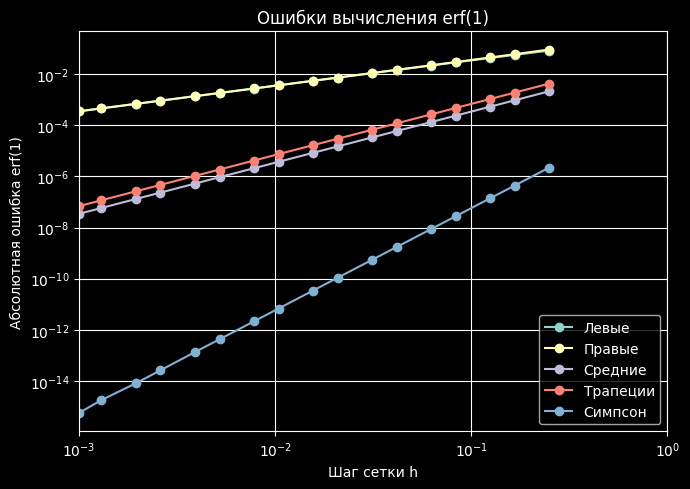

In [98]:
h_values_erf = x_erf / N_values_erf

plt.figure(figsize=(7, 5))
for name, method in methods:
    plt.loglog(h_values_erf, errors_erf[name], "o-", label=name)
# Нулевые ошибки пропускаем: логарифм нуля не определён.
plt.yscale("log", nonpositive="mask")
# Деления оси X: степени десяти от 10^-3 до 10^0.
plt.xlim(1e-3, 1)
plt.xticks([1e-3, 1e-2, 1e-1, 1],
           [r"$10^{-3}$", r"$10^{-2}$", r"$10^{-1}$", r"$10^0$"])
plt.minorticks_off()
plt.xlabel("Шаг сетки h")
plt.ylabel("Абсолютная ошибка erf(1)")
plt.title("Ошибки вычисления erf(1)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Проверка свойств функции:

Из определения следуют $\operatorname{erf}(0)=0$ и
$\operatorname{erf}(-x)=-\operatorname{erf}(x)$, поскольку $e^{-t^2}$ — чётная функция.
Проверим эти свойства и максимальную ошибку на выбранных точках.

In [99]:
print("erf(0) =", find_erf(0, N_erf))
print("erf(-1) + erf(1) =", find_erf(-1, N_erf) + find_erf(1, N_erf))

max_error = 0
for x in x_values:
    error = abs(find_erf(x, N_erf) - math.erf(x))
    if error > max_error:
        max_error = error

print("Максимальная ошибка Симпсона:", max_error)

erf(0) = 0.0
erf(-1) + erf(1) = 0.0
Максимальная ошибка Симпсона: 2.737469140257076e-10
